<a href="https://colab.research.google.com/github/tanvi118/AISR_LAB/blob/main/Robotics_Exp_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tanvi Vitankar, 500120658, exp-8

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [2]:
# True values
true_value = 10

# Noisy measurements
measurements = true_value + np.random.normal(
    0,
    2,
    50
)

# Initial estimate
estimate = 0

# Estimate uncertainty
P = 1


In [3]:
# Process noise
Q = 0.01

# Measurement noise
R = 4

estimates = []


for measurement in measurements:

    # Prediction
    predicted_estimate = estimate
    predicted_P = P + Q

    # Kalman Gain
    K = predicted_P / (predicted_P + R)

    # Update estimate
    estimate = predicted_estimate + K * (
        measurement - predicted_estimate
    )

    # Update uncertainty
    P = (1 - K) * predicted_P

    estimates.append(estimate)

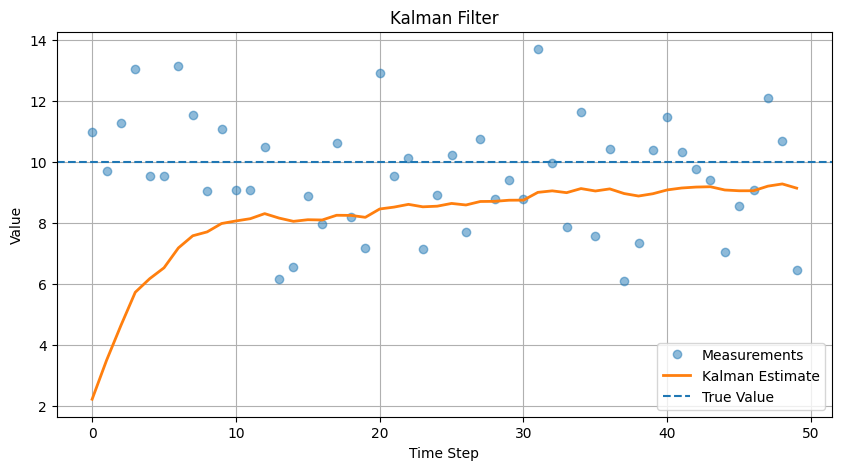

In [4]:
plt.figure(figsize=(10, 5))

plt.plot(
    measurements,
    'o',
    label="Measurements",
    alpha=0.5
)

plt.plot(
    estimates,
    label="Kalman Estimate",
    linewidth=2
)

plt.axhline(
    true_value,
    linestyle="--",
    label="True Value"
)

plt.xlabel("Time Step")
plt.ylabel("Value")
plt.title("Kalman Filter")
plt.legend()
plt.grid()

plt.show()